# World Population Exploratory Data Analysis (EDA)

## Project Overview
This project explores population data collected from Wikipedia to identify patterns, examine population distributions, investigate anomalies, and validate assumptions using descriptive statistics, visualizations, and statistical testing.

## Objectives
- Understand the dataset's structure and variables.
- Identify patterns and differences in population sizes.
- Investigate potential anomalies and data-quality issues.
- Test a meaningful statistical hypothesis.
- Communicate findings and limitations.

## Data Source
[Wikipedia: List of countries and dependencies by population](https://en.wikipedia.org/wiki/List_of_countries_and_dependencies_by_population)

## Tools
Python, pandas, NumPy, Matplotlib, Seaborn, and SciPy.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from google.colab import files

uploaded = files.upload()

Saving CodeAlpha_World Population_Webscraping.csv to CodeAlpha_World Population_Webscraping.csv


In [4]:
df = pd.read_csv("CodeAlpha_World Population_Webscraping.csv")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully!
Rows and columns: (240, 6)


,Location,Population,% of world,Date,Source (official or from the United Nations),Year
0,World,8232000000,100.0,13 Jun 2025,UN projection,2025
1,India,1429404000,17.3,1 Jul 2026,Official projection,2026
2,China,1404890000,17.0,31 Dec 2025,Official estimate,2025
3,United States,341784857,4.1,1 Jul 2025,Official estimate,2025
4,Indonesia,288315089,3.5,31 Dec 2025,National annual projection,2025


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 6 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   Location                                      240 non-null    object 
 1   Population                                    240 non-null    int64  
 2   % of world                                    240 non-null    float64
 3   Date                                          240 non-null    object 
 4   Source (official or from the United Nations)  240 non-null    object 
 5   Year                                          240 non-null    int64  
dtypes: float64(1), int64(2), object(3)
memory usage: 11.4+ KB


In [6]:
df.describe()

,Population,% of world,Year
count,2.400000e+02,240.000000,240.000000
mean,6.794023e+07,0.819036,2024.662500
std,5.461313e+08,6.633171,1.683867
min,3.500000e+01,0.000000,2020.000000
25%,3.893190e+05,0.004750,2024.000000
50%,5.597000e+06,0.070000,2025.000000
75%,2.339219e+07,0.300000,2026.000000
max,8.232000e+09,100.000000,2026.000000


In [7]:
df["Year"].value_counts().sort_index()

,count
Year,
2020,5
2021,16
2022,14
2023,14
2024,32
2025,49
2026,110


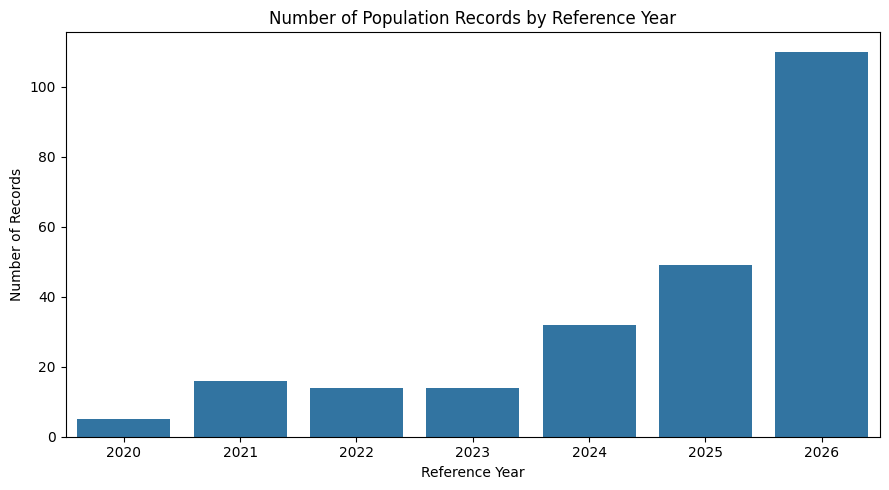

In [8]:
year_counts = df["Year"].value_counts().sort_index()

plt.figure(figsize=(9, 5))
sns.barplot(x=year_counts.index, y=year_counts.values)

plt.title("Number of Population Records by Reference Year")
plt.xlabel("Reference Year")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

In [9]:
# Create a separate dataset without the global total
locations_df = df[df["Location"] != "World"].copy()

print("Total records:", len(df))
print("Country and territory records:", len(locations_df))

print("\nPopulation summary excluding World:")
print(locations_df["Population"].describe())

Total records: 240
Country and territory records: 239

Population summary excluding World:
count    2.390000e+02
mean     3.378099e+07
std      1.352442e+08
min      3.500000e+01
25%      3.821380e+05
50%      5.557096e+06
75%      2.310823e+07
max      1.429404e+09
Name: Population, dtype: float64


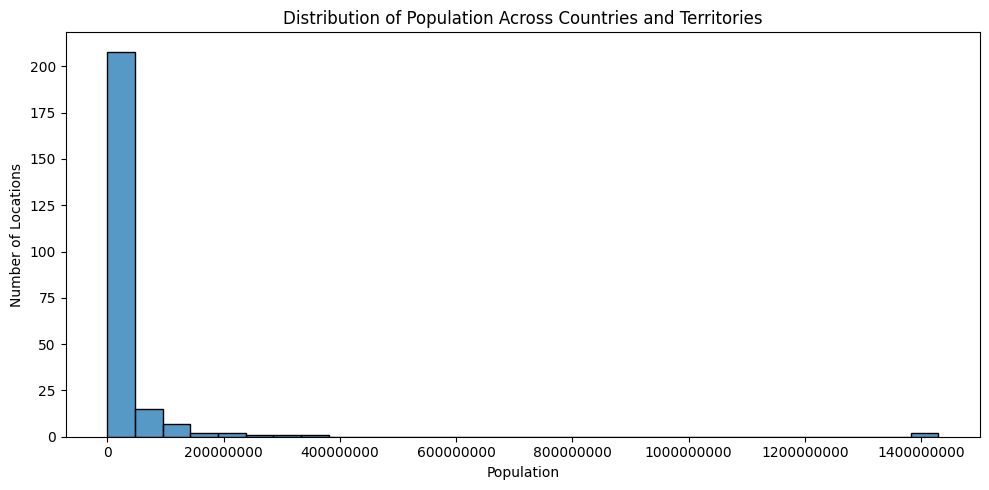

In [10]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=locations_df,
    x="Population",
    bins=30
)

plt.title("Distribution of Population Across Countries and Territories")
plt.xlabel("Population")
plt.ylabel("Number of Locations")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()

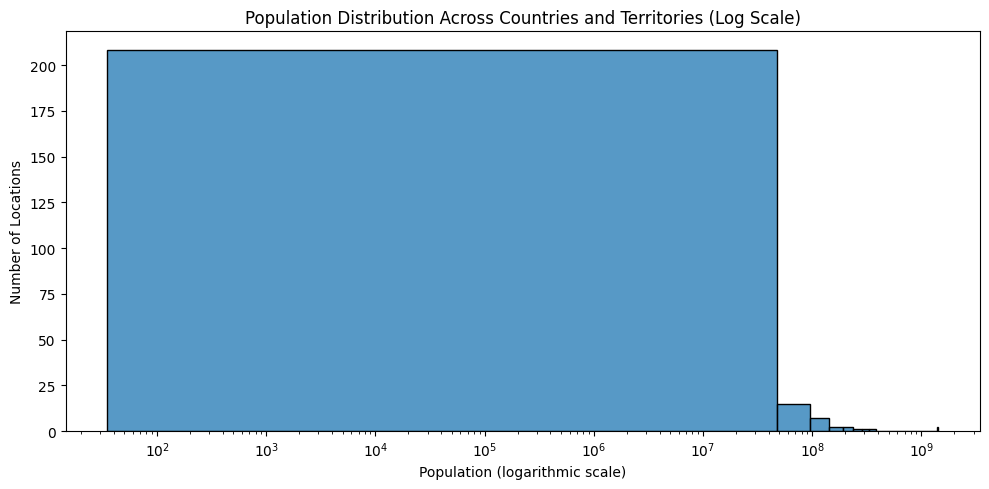

In [11]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=locations_df,
    x="Population",
    bins=30
)

plt.xscale("log")
plt.title("Population Distribution Across Countries and Territories (Log Scale)")
plt.xlabel("Population (logarithmic scale)")
plt.ylabel("Number of Locations")
plt.tight_layout()
plt.show()

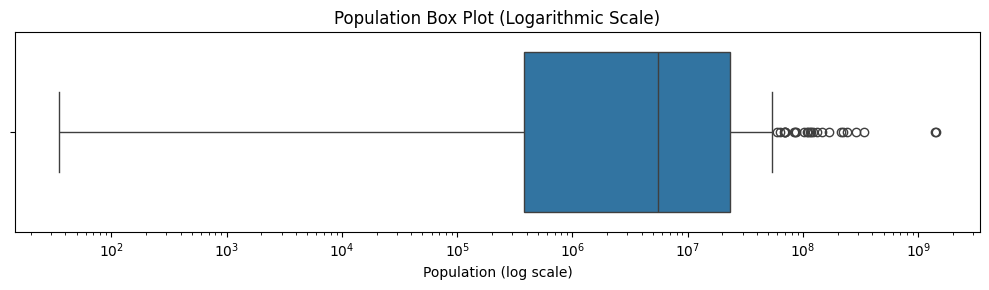

In [12]:
plt.figure(figsize=(10, 3))

sns.boxplot(x=locations_df["Population"])

plt.xscale("log")
plt.title("Population Box Plot (Logarithmic Scale)")
plt.xlabel("Population (log scale)")
plt.tight_layout()
plt.show()


Question: How widely do population sizes vary, and is the distribution skewed?


The population box plot on a logarithmic scale shows a highly uneven distribution across countries and territories. Most locations have considerably smaller populations than the most populous countries, while a few locations appear as potential statistical outliers.

# Examined descriptive statistics, a histogram, a log-scale histogram, and a box plot. The distribution is strongly right-skewed, with a few very highly populated locations.

In [13]:
top5 = locations_df.nlargest(5, "Population")[
    ["Location", "Population", "Year", "% of world"]
]

display(top5)

,Location,Population,Year,% of world
1,India,1429404000,2026,17.3
2,China,1404890000,2025,17.0
3,United States,341784857,2025,4.1
4,Indonesia,288315089,2025,3.5
5,Pakistan,241499431,2023,2.9


Qustion:
Which locations have the largest populations, and how much of the global population do the five most populous countries represent?

Answer:
### Top Five Most Populous Locations

## India has the largest recorded population in the dataset, followed by China, the United States, Indonesia, and Pakistan. ***India and China together account for 34.3% of the reported world population share, indicating that a substantial proportion of the global population is concentrated in these two countries.***

The difference between the populations of India and China is relatively small compared with the gap between China and the United States. However, the records have different reference years, which limits the accuracy of direct comparisons. These findings describe the available dataset rather than a synchronized population ranking for a single year.

In [14]:
# Get the reported world population
world_total = df.loc[df["Location"] == "World", "Population"].iloc[0]

# Calculate each location's expected percentage of the world population
locations_df["Calculated % of world"] = (
    locations_df["Population"] / world_total * 100
)

# Compare reported and calculated percentages
locations_df["Percentage difference"] = (
    locations_df["% of world"] - locations_df["Calculated % of world"]
)

display(
    locations_df[
        ["Location", "Population", "% of world",
         "Calculated % of world", "Percentage difference"]
    ].head(10).round(3)
)

,Location,Population,% of world,Calculated % of world,Percentage difference
1,India,1429404000,17.3,17.364,-0.064
2,China,1404890000,17.0,17.066,-0.066
3,United States,341784857,4.1,4.152,-0.052
4,Indonesia,288315089,3.5,3.502,-0.002
5,Pakistan,241499431,2.9,2.934,-0.034
6,Nigeria,223800000,2.7,2.719,-0.019
7,Brazil,214211951,2.6,2.602,-0.002
8,Bangladesh,169828911,2.1,2.063,0.037
9,Russia,146028325,1.8,1.774,0.026
10,Mexico,131231919,1.6,1.594,0.006


In [15]:
# Calculate the absolute difference for each location
locations_df["Absolute difference"] = (
    locations_df["Percentage difference"].abs()
)

# Summarize the differences
print("Mean absolute difference:",
      locations_df["Absolute difference"].mean().round(4))

print("Maximum absolute difference:",
      locations_df["Absolute difference"].max().round(4))

# Count records with differences greater than 0.05 percentage points
large_differences = locations_df[
    locations_df["Absolute difference"] > 0.05
]

print("Records with differences greater than 0.05 percentage points:",
      len(large_differences))

display(
    large_differences[
        ["Location", "Population", "% of world",
         "Calculated % of world", "Percentage difference"]
    ].sort_values("Absolute difference", ascending=False).head(10).round(3)
)

Mean absolute difference: 0.0129


AttributeError: 'float' object has no attribute 'round'

In [16]:
# Calculate the absolute difference for each location
locations_df["Absolute difference"] = (
    locations_df["Percentage difference"].abs()
)

# Summarize the differences
print("Mean absolute difference:",
      round(locations_df["Absolute difference"].mean(), 4))

print("Maximum absolute difference:",
      round(locations_df["Absolute difference"].max(), 4))

# Count records with differences greater than 0.05 percentage points
large_differences = locations_df[
    locations_df["Absolute difference"] > 0.05
]

print("Records with differences greater than 0.05 percentage points:",
      len(large_differences))

display(
    large_differences[
        ["Location", "Population", "% of world",
         "Calculated % of world", "Percentage difference"]
    ].sort_values("Absolute difference", ascending=False).head(10).round(3)
)

Mean absolute difference: 0.0129
Maximum absolute difference: 0.0662
Records with differences greater than 0.05 percentage points: 8


KeyError: 'Absolute difference'

In [17]:
display(
    large_differences[
        ["Location", "Population", "% of world",
         "Calculated % of world", "Percentage difference",
         "Absolute difference"]
    ].sort_values(
        "Absolute difference", ascending=False
    ).head(10).round(3)
)

,Location,Population,% of world,Calculated % of world,Percentage difference,Absolute difference
2,China,1404890000,17.0,17.066,-0.066,0.066
1,India,1429404000,17.3,17.364,-0.064,0.064
14,Ethiopia,111652998,1.3,1.356,-0.056,0.056
20,Thailand,70250751,0.8,0.853,-0.053,0.053
41,Poland,37232000,0.4,0.452,-0.052,0.052
3,United States,341784857,4.1,4.152,-0.052,0.052
21,Tanzania,70038850,0.8,0.851,-0.051,0.051
64,Kazakhstan,20618796,0.2,0.250,-0.050,0.050


Question:
Do the reported % of world values agree with the population figures?

### Data Consistency Findings

The reported percentages of the world population were compared with percentages calculated using each location's population and the dataset's reported World population total.

The mean absolute difference was approximately 0.0129 percentage points, while the maximum absolute difference was approximately 0.0662 percentage points. Eight of the 239 country and territory records had absolute differences greater than 0.05 percentage points.

China and India showed the largest differences among the identified records. Although the differences were small in absolute terms, the results suggest that rounding alone may not explain every discrepancy. Different reference dates, population estimates, or source methodologies may contribute to these differences.

## This comparison has a limitation: the records use different reference years, while the calculations use one World population total. The results therefore identify potential inconsistencies for further investigation rather than proving that the reported percentages are incorrect.

In [18]:
year_summary = (
    df["Year"]
    .value_counts()
    .sort_index()
    .rename_axis("Reference Year")
    .reset_index(name="Number of Records")
)

year_summary["Percentage of Records"] = (
    year_summary["Number of Records"] / len(df) * 100
).round(2)

display(year_summary)

,Reference Year,Number of Records,Percentage of Records
0,2020,5,2.08
1,2021,16,6.67
2,2022,14,5.83
3,2023,14,5.83
4,2024,32,13.33
5,2025,49,20.42
6,2026,110,45.83


Questions:
How many records use each reference year, and could the differing dates affect comparisons?

### Reference Year Findings

*The dataset contains 240 records distributed across reference years from 2020 to 2026. The year 2026 accounts for the largest share, with 110 records (45.83%), followed by 2025 with 49 records (20.42%). Together, these two years represent 66.25% of all records. The year 2020 has the fewest records, with 5 (2.08%).*

The uneven distribution indicates that the dataset contains population estimates from different reference periods. These differences can limit direct comparisons because populations may change over time, and sources may use different estimation methods. Therefore, population rankings and percentage-consistency checks should be interpreted with the reference year and source information in mind.

## The reference-year counts describe the temporal coverage of the dataset; they do not establish population growth rates or trends.

In [19]:
from scipy.stats import shapiro

# Log-transform population values, excluding the World total
log_population = np.log10(locations_df["Population"])

# Perform the Shapiro-Wilk normality test
statistic, p_value = shapiro(log_population)

print("Shapiro-Wilk statistic:", round(statistic, 4))
print("P-value:", p_value)

# Interpret the result at the 5% significance level
if p_value <= 0.05:
    print("Decision: Reject the null hypothesis.")
    print("The log-transformed population values are not normally distributed.")
else:
    print("Decision: Fail to reject the null hypothesis.")
    print("There is insufficient evidence to conclude that the values differ from a normal distribution.")

Shapiro-Wilk statistic: 0.9527
P-value: 4.813998160009991e-07
Decision: Reject the null hypothesis.
The log-transformed population values are not normally distributed.


### Statistical Hypothesis Test: Normality of Log-Transformed Population

A Shapiro–Wilk test was conducted on the base-10 logarithm of population values for 239 countries and territories, excluding the World total.

- **Null hypothesis (H₀):** The log-transformed population values are drawn from a normally distributed population.
- **Alternative hypothesis (H₁):** The log-transformed population values are not drawn from a normally distributed population.
- **Significance level:** 0.05
- **Test statistic:** W = 0.9527
- **P-value:** 4.81 × 10⁻⁷

Since the p-value is below 0.05, the null hypothesis was rejected. The results provide strong evidence that the log-transformed population values are not normally distributed. This indicates that the logarithmic transformation did not fully produce a normal distribution.

The finding supports the need to interpret population distributions carefully and consider their shape when selecting statistical methods. It does not, by itself, establish the degree of skewness or identify the cause of the distribution.

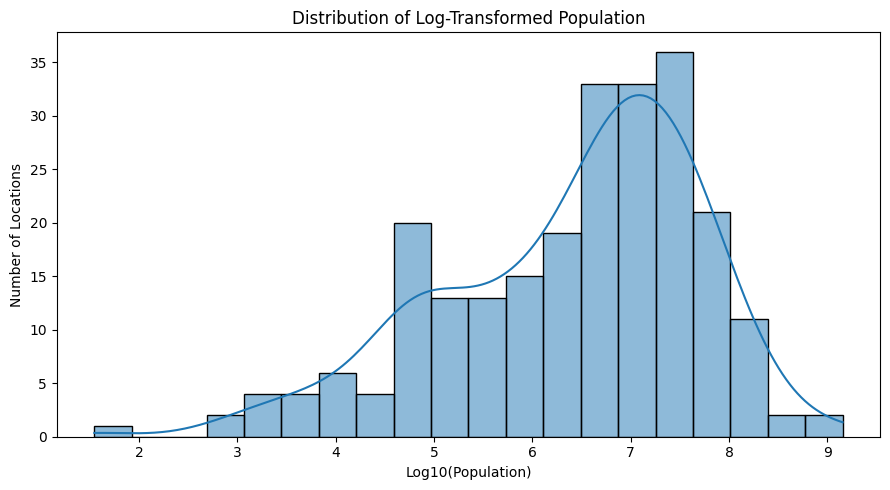

In [20]:
plt.figure(figsize=(9, 5))

sns.histplot(log_population, bins=20, kde=True)

plt.title("Distribution of Log-Transformed Population")
plt.xlabel("Log10(Population)")
plt.ylabel("Number of Locations")

plt.tight_layout()
plt.show()

### Log-Transformed Population Distribution

The histogram of log-transformed population values rises to a peak before declining. Although the logarithmic transformation makes the population distribution easier to examine, the resulting shape does not appear to be perfectly bell-shaped. This visual observation is consistent with the Shapiro–Wilk test, which rejected the null hypothesis of normality at the 5% significance level (W = 0.9527, p < 0.001).

Together, the visualization and statistical test suggest that the log transformation did not fully normalize the distribution. Population sizes therefore remain unevenly distributed across countries and territories.

# World Population Exploratory Data Analysis — Key Findings

## 1. Population Concentration

The dataset contains 240 records, including the global population total and 239 country and territory records. India has the largest recorded population at approximately 1.429 billion, followed by China at approximately 1.405 billion. The United States, Indonesia, and Pakistan complete the five largest available records.

India and China together account for 34.3% of the reported global population share, indicating a substantial concentration of the world's population in these two countries.

However, the records use different reference years, so the ranking does not represent a perfectly synchronized comparison for one date.

## 2. Population Distribution

Population sizes vary considerably across countries and territories. The descriptive statistics and histograms show a strongly right-skewed distribution: most locations have much smaller populations than the largest countries.

Excluding the World total, the median population is approximately 5.56 million, while the mean is approximately 33.78 million. The much higher mean reflects the influence of a relatively small number of highly populated locations.

A Shapiro–Wilk test on the base-10 logarithm of population values produced a test statistic of 0.9527 and a p-value of approximately 4.81 × 10⁻⁷. At the 5% significance level, the null hypothesis of normality was rejected. This indicates that the log transformation did not fully produce a normally distributed dataset.

## 3. Data Consistency

The reported percentage of the world's population was compared with a calculated percentage based on each location's population and the dataset's reported global population total.

The mean absolute difference was approximately 0.0129 percentage points, and the maximum absolute difference was approximately 0.0662 percentage points. Eight of the 239 country and territory records had absolute differences greater than 0.05 percentage points.

Overall, the reported percentages were generally close to the calculated values. However, the larger differences suggest that rounding alone may not explain every discrepancy. Differences in reference dates, population estimates, and source methodologies may also contribute.

Because the locations have different reference years while the calculations use one global population figure, these results identify potential discrepancies rather than proving that any reported value is incorrect.

## 4. Reference Years

The dataset includes records with reference years from 2020 through 2026. The largest number of records belongs to 2026, with 110 records (45.83%), followed by 2025, with 49 records (20.42%). Together, these years account for 66.25% of the dataset. The year 2020 has the fewest records, with five (2.08%).

The uneven distribution shows that the dataset contains estimates from different reference periods. This limits direct comparisons because population figures may refer to different dates and may be based on different estimation methods.

The year counts describe the dataset's temporal coverage; they do not demonstrate population growth rates.

## Conclusion

The analysis shows that population sizes differ substantially across countries and territories, with India and China accounting for a large share of the reported global population. Population values are strongly right-skewed, and a formal normality test found that the log-transformed values were not normally distributed.

The reported global population percentages are generally close to independently calculated values, although a small number of records show larger differences that warrant further investigation. Reference years also vary considerably, making it important to consider dates and source methodologies when interpreting comparisons.

Overall, the project demonstrates how descriptive statistics, visualization, and hypothesis testing can reveal patterns and potential data-quality issues. The findings should be interpreted in light of the dataset's mixed reference dates, varied sources, and inclusion of both countries and dependencies.